# AP 155 Lab Exercise
---
## Exercise 8: Minimization

_Instructions_: 
- **Report figure:** A 2 by 2 figure plot. Upper row contains the plot of the actual functions. Lower row contains a plot of their derivatives. Use markers to plot the found local extrema by the golden section search algorithm.  
- **Report discussion:** What happens if a number other than the golden ratio is used to perform the *golden* section search algorithm?
- **Code**: Complete the code and ensure it is functional, error-free, readable, and efficient (where needed). Include concise Markdown documentation highlighting the critical steps of your algorithm for each problem.

### Student Information
- _Full Name (Last Name, First Name)_: Rivera, Kyle Florian
- _Student No._: 2024-16197
- _Section_: THU-TX-1

### Grading Information (c/o Lab Instructor)
- [Rubrics description link](https://drive.google.com/file/d/1BMSlPot2Mc7XLu0eo4S8I8gLBsIadbCL/view?usp=sharing) (Note: percentages may still be tweaked)

| Criteria | Score | Subtotal |
| --- | --- | --- |
| Report figure | XX | 20 |
| Report discussion | XX | 20|
| Code readability | XX | 20 |
| Code efficiency | XX | 20 | 
| Code appropriateness  | XX | 20 | 
| **TOTAL** | XXX | 100 |

_Date and Time Scored (MM/DD/YYYY HH:MM AM/PM):_:_

---
## Section 1: Report

### Report figure

![Figure 1: Extrema of the two functions](extrema.png)

Figure 1: Calculated extrema of $\phi(x)$ and $f(x)$ and their corresponding $(x, f'(x))$ points.

![Figure 2: Extrema of the two functions across various golden ratios](ratios.png)

Figure 2: Extrema of $\phi(x)$ and $f(x)$ found by section search using different ratios in place of the golden ratio. Colors indicate the ratio while squares and circle markers show minima and maxima.

### Report discussion

TThe search returns the correct extrema only for the golden ratio. For a ratio below 1 (e.g. $0.01$), the two interior points swap order, so the algorithm discards the section that contains the extremum and converges to an endpoint of the initial interval. For a ratio of exactly 1, both interior points coincide at the midpoint, the comparison gives no information, and the search again collapses onto an endpoint. For very large ratios ($10^3$, $10^6$), the interior points lie almost on the endpoints, so the interval shrinks by only a factor of about $1/\text{ratio}$ per iteration and the search fails to converge within $1000$ iterations (the default we assigned). The golden ratio is works because one interior point of the current interval becomes an interior point of the next, which then shrinks the interval by a constant factor of about $0.618$.

### Other comments
- Nice problem

---
## Section 2: Code

### Problem 1: Minimization

Consider the following equations:

Eq. 5.91
$$
\phi(x) = x^4 - 9x^3 + 25x^2 - 24x + 4
$$

Eq. 5.145
$$
f(x) = -x^5 + 4x^4 - 4x^3 + x^2 e^x - 2x^2 - 4xe^x + 8x + 4e^x - 8
$$

1. Plot each of the functions. Get a rough estimate of the local minima and maxima
2. Implement 5.5.2.2 (golden section search), then determine the local minima and maxima of Eq. 5.91 and Eq. 5.145.
3. Report figure: A 2 by 2 figure plot. Upper row contains the plot of the actual functions. Lower row contains a plot of their derivatives. Use markers to plot the found local extrema by the golden section search algorithm. 

In [1]:
import numpy as np
import matplotlib.pyplot as plt

Let us first define the functions and its derivatives before plotting each.
$$
\begin{align}
    \phi(x) &= x^4 - 9x^3 + 25x^2 - 24x + 4 \\
    \phi'(x) &= 4x^3 - 27x^2 + 50x - 24 \\ \\
    f(x) &= -x^5 + 4x^4 - 4x^3 + x^2 e^x - 2x^2 -4xe^x + 8x + 4e^x -8 \\
    f'(x) &= -5x^4 + 16x^3 - 12x^2 + x^2 e^x - 2xe^x - 4x + 8
\end{align}
$$


In [2]:
def phi(x):
    return x**4 - (9* x**3) + (25* x**2) - (24*x) + 4 

def phi_d(x):
    return (4*x**3) - (27*x**2) + 50*x - 24

def f(x):
    return (-x**5) + (4*x**4) - (4*x**3) + (x**2*np.exp(x)) - (2*x**2) - (4*x*np.exp(x)) + (8*x) + (4*np.exp(x)) - 8 

def f_d(x):
    return (-5*x**4) + (16*x**3) - (12*x**2) + (x**2 * np.exp(x)) - (2*x*np.exp(x)) - (4*x) + 8 

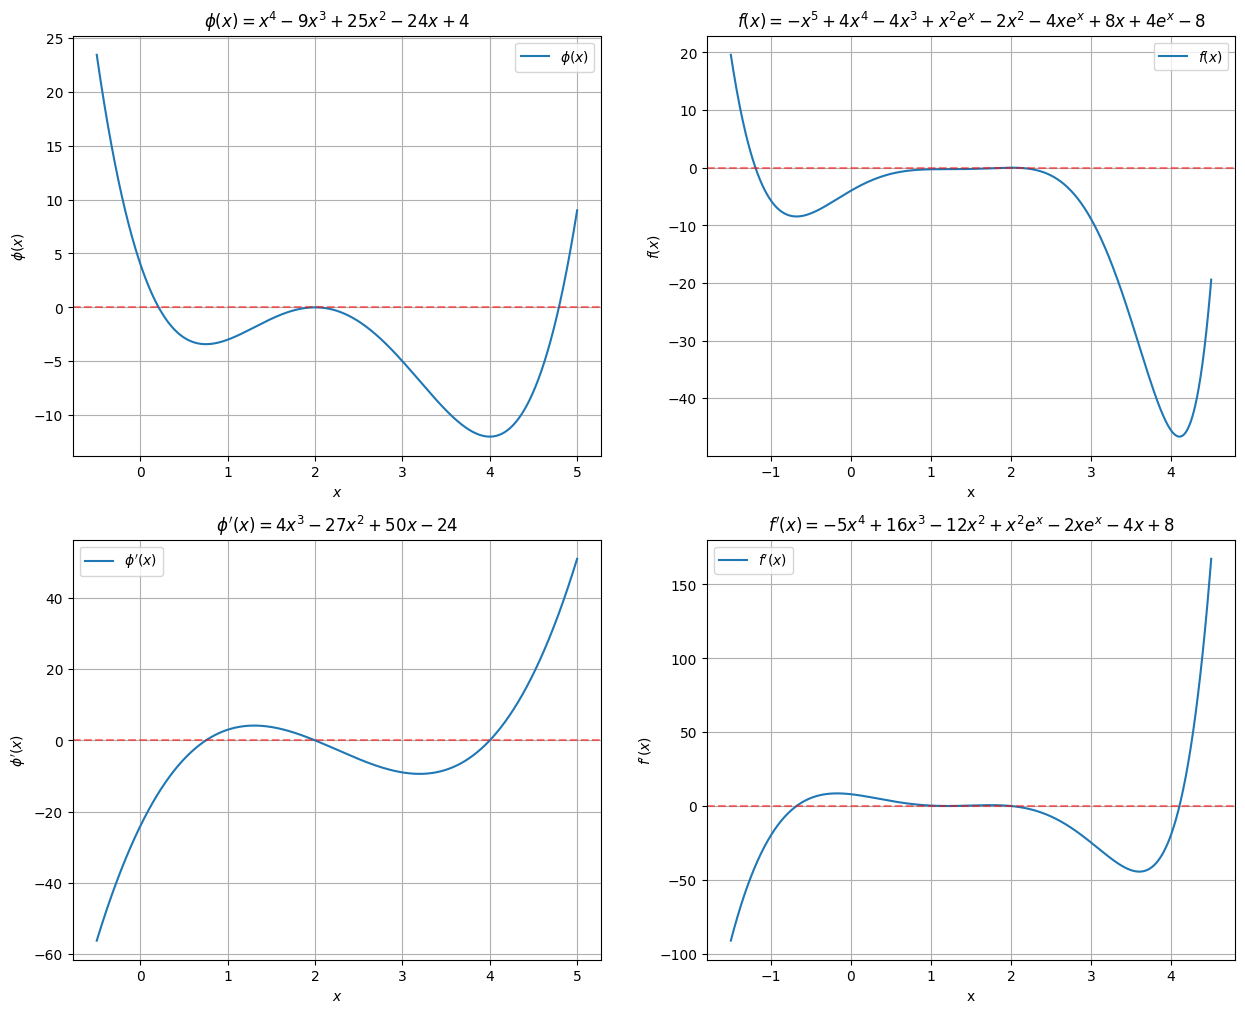

In [3]:
x_1 = np.linspace(-0.5, 5, 5000)
y_1 = phi(x_1)
y_1p = phi_d(x_1)

x_2 = np.linspace(-1.5, 4.5, 1000)
y_2 = f(x_2)
y_2p = f_d(x_2)

fig, axs = plt.subplots(2, 2, figsize = (15, 12))

# ------------------------------------
# phi(x)
# ------------------------------------
axs[0,0].plot(x_1, y_1, label=r'$\phi(x)$')
axs[0,0].axhline(y=0, alpha=0.5, c="red", ls="--")
axs[0,0].set_title(r'$\phi(x) = x^4 - 9x^3 + 25x^2 - 24x + 4$')
axs[0,0].set_xlabel('$x$')
axs[0,0].set_ylabel(r'$\phi(x)$')
axs[0,0].legend()
axs[0,0].grid(True)

# phi_d(x)
axs[1,0].plot(x_1, y_1p, label=r"$\phi'(x)$")
axs[1,0].axhline(y=0, alpha=0.5, c="red", ls="--")
axs[1,0].set_title(r"$\phi'(x) = 4x^3 - 27x^2 + 50x - 24$")
axs[1,0].set_xlabel('$x$')
axs[1,0].set_ylabel(r"$\phi'(x)$")
axs[1,0].legend()
axs[1,0].grid(True)

# ------------------------------------
# f(x)
# ------------------------------------
axs[0,1].plot(x_2,y_2, label=r'$f(x)$')
axs[0,1].axhline(y=0, alpha=0.5, c="red", ls="--")
axs[0,1].set_title(r'$f(x) = -x^5 + 4x^4 - 4x^3 + x^2 e^x - 2x^2 - 4xe^x + 8x + 4e^x - 8$')
axs[0,1].set_xlabel('x')
axs[0,1].set_ylabel(r'$f(x)$')
axs[0,1].legend()
axs[0,1].grid(True)

# f_d(x)
axs[1,1].plot(x_2,y_2p, label=r"$f'(x)$")
axs[1,1].axhline(y=0, alpha=0.5, c="red", ls="--")
axs[1,1].set_title(r"$f'(x) = -5x^4 + 16x^3 - 12x^2 + x^2 e^x - 2xe^x - 4x + 8$")
axs[1,1].set_xlabel('x')
axs[1,1].set_ylabel(r"$f'(x)$")
axs[1,1].legend()
axs[1,1].grid(True)

plt.show()

In [4]:
golden_ratio = 0.5*(1 + np.sqrt(5))
tolerance = 1e-6

def golden_search(minimum=True, func=phi, lower=0, upper=2, iterations=1000, tol=tolerance, varphi=golden_ratio):
    x0 = lower
    x1 = upper
    ratio_plusone = (varphi + 1)
    # calculate x2 and x3
    x2 = x0 + (x1-x0) / ratio_plusone
    x3 = x0 + ((x1-x0)*varphi) / ratio_plusone 
    y2 = func(x2)
    y3 = func(x3)
    xmin = (x0+x1)/2
    for i in range(1, iterations):
        # adjusts bounds based on function value
        if (y3 < y2) == minimum: # the following is discussed below
            # extremum is in [x2, x1]: the old x3 becomes the new x2, so only x3 is new
            x0 = x2
            x2, y2 = x3, y3
            x3 = x0 + (x1-x0)*varphi / ratio_plusone
            y3 = func(x3)
        else:
            # extremum is in [x0, x3]: the old x2 becomes the new x3, so only x2 is new
            x1 = x3
            x3, y3 = x2, y2
            x2 = x0 + (x1-x0) / ratio_plusone
            y2 = func(x2)
        xmin = (x0+x1)/2
        if abs(x1-x0) < tol: # if the points are close enough (less than tolerance), we stop!
            break
    return xmin

In order to condense the code and not have different functions, we ask if we are seraching for minimum and maximum. In the book the implementation would be as follows:

    if minimum:
        if func(x3) < func(x2):
            x0 = x2
        else: 
            x1 = x3
    else:
        if func(x3) < func(x2):
            x1 = x3
        else: 
            x0 = x2

But we can actually condense this (using a truth table) into the following:

    if (func(x3) < func(x2)) == minimum: 
        x0 = x2
    else:
        x1 = x3

_Note: `minimum` is boolean. If `True`, we are searching for the minimum, otherwise, we are looking for the maximum_

Furthermore, we modified the program (as mentioned in Problem 5.25) such that we only need to evaluate the function once per iteration and not twice (hence why the explanation is a bit different on the actual code).

Let us now use this in order to search for the extremum

In [5]:
# finding the minimums
phi_min1 = golden_search(func=phi, lower=-0.5, upper=2)
phi_min2 = golden_search(func=phi, lower=2.5, upper=5)
phi_min = np.array([phi_min1, phi_min2])

f_min1 = golden_search(func=f, lower=-1, upper=0)
f_min2 = golden_search(func=f, lower=3.5, upper=5.5)
f_min = np.array([f_min1, f_min2])
print(f"x-values of minimum of phi(x): {phi_min}\nx-values of minimum of f(x): {f_min}")

# finding the maximums
phi_max = np.array(golden_search(func=phi, lower=1, upper=3, minimum=False))
f_max = np.array(golden_search(func=f, lower=0, upper=3, minimum=False))
print(f"x-values of maximum of phi(x): {phi_max}\nx-values of maximum of f(x): {f_max}")

x-values of minimum of phi(x): [0.75000026 3.99999988]
x-values of minimum of f(x): [-0.67986224  4.10332488]
x-values of maximum of phi(x): 2.000000205303103
x-values of maximum of f(x): 2.000000087674892


And now we plot the extrema

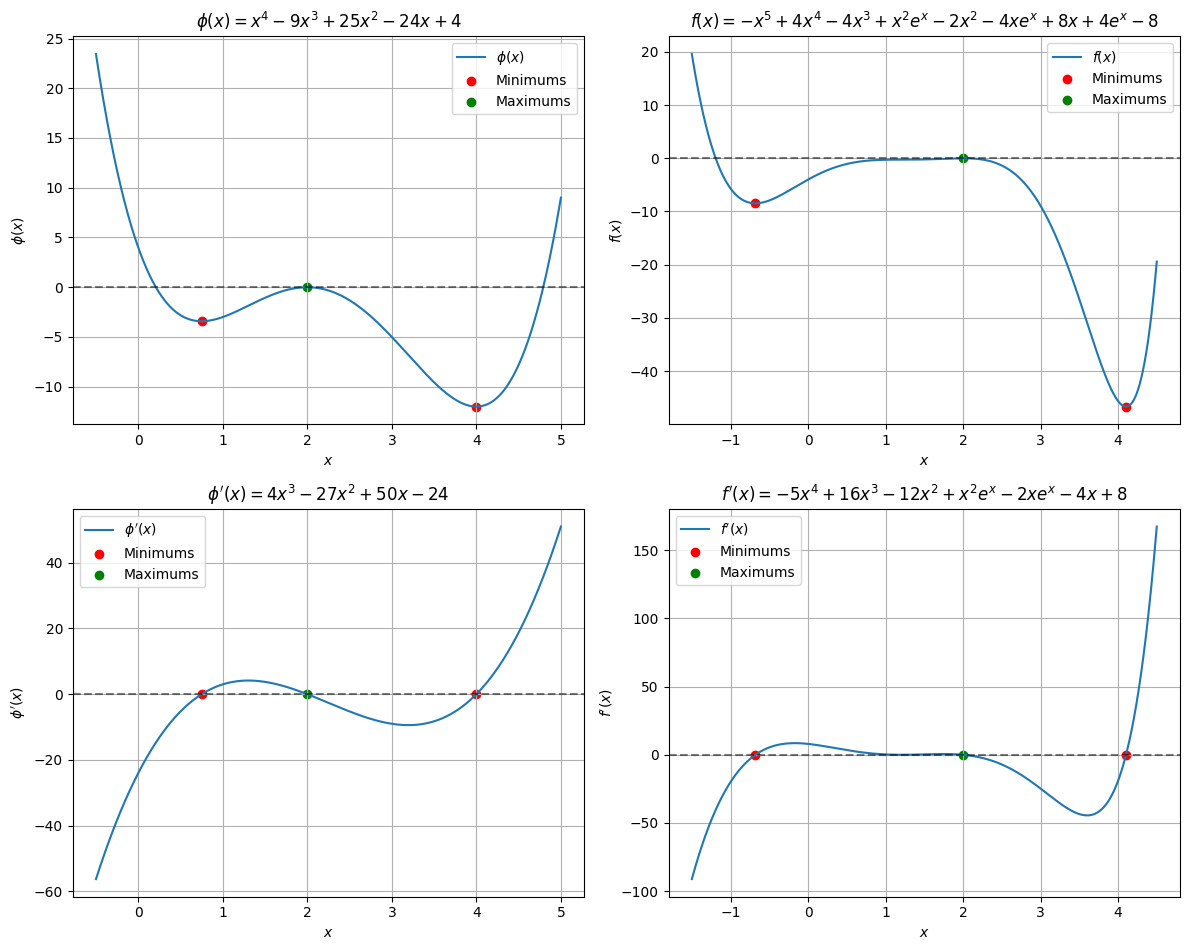

In [6]:
x_1 = np.linspace(-0.5, 5, 5000)
y_1, y_1p = phi(x_1), phi_d(x_1)

x_2 = np.linspace(-1.5, 4.5, 1000)
y_2, y_2p = f(x_2), f_d(x_2) 

fig, [[ax1, ax3], [ax2, ax4]] = plt.subplots(2, 2, figsize = (12, 9.6))

# self explanatory
plot_config = [(ax1, x_1, y_1, r'$\phi(x)$', r'$\phi(x) = x^4 - 9x^3 + 25x^2 - 24x + 4$', r'$\phi(x)$'),
               (ax2, x_1, y_1p, r"$\phi'(x)$", r"$\phi'(x) = 4x^3 - 27x^2 + 50x - 24$", r"$\phi'(x)$"),
               (ax3, x_2, y_2, r'$f(x)$', r'$f(x) = -x^5 + 4x^4 - 4x^3 + x^2 e^x - 2x^2 - 4xe^x + 8x + 4e^x - 8$', r'$f(x)$'),
               (ax4, x_2, y_2p, r"$f'(x)$", r"$f'(x) = -5x^4 + 16x^3 - 12x^2 + x^2 e^x - 2xe^x - 4x + 8$", r"$f'(x)$")]

functions = [phi, phi_d, f, f_d]
minimums = [phi_min, phi_min, f_min, f_min]
maximums = [phi_max, phi_max, f_max, f_max]

# we plot the corresponding ordered pairs where the min/max occurs and see (visually) if it actually falls into where the derivative is zero.
for (ax, x, y, label, title, ylabel), mins, maxs, func in zip(plot_config, minimums, maximums, functions):
    ax.plot(x, y, label=label)
    ax.axhline(y=0, c='black', ls='--', alpha=0.5)
    ax.scatter(mins, func(mins), c='red', label='Minimums')
    ax.scatter(maxs, func(maxs), c='green', label='Maximums')
    ax.set_title(title)
    ax.set_xlabel('$x$')
    ax.set_ylabel(ylabel)
    ax.legend()
    ax.grid(True)

plt.tight_layout()
plt.savefig("extrema.png", dpi=600)
plt.show()

--- ratio = 0.01 ---
x-values of minimum of phi(x): [-0.47549018  4.97549018]
x-values of minimum of f(x): [-0.00980345  4.49019655]
x-values of maximum of phi(x): 2.9803921474413686
x-values of maximum of f(x): 2.9705882211620533
--- ratio = 1 ---
x-values of minimum of phi(x): [0.33333343 3.33333343]
x-values of minimum of f(x): [-0.83333349  3.83333349]
x-values of maximum of phi(x): 2.3333334922790527
x-values of maximum of f(x): 1.5
--- ratio = 1.618033988749895 ---
x-values of minimum of phi(x): [0.75000026 3.99999988]
x-values of minimum of f(x): [-0.67986224  4.10332486]
x-values of maximum of phi(x): 2.000000205303103
x-values of maximum of f(x): 2.000000087674892
--- ratio = 1000.0 ---
x-values of minimum of phi(x): [1.99750374 2.50249626]
x-values of minimum of f(x): [-0.9990015  3.5009985]
x-values of maximum of phi(x): 1.0019970042440094
x-values of maximum of f(x): 0.002995507017375253
--- ratio = 1000000.0 ---
x-values of minimum of phi(x): [1.9999975 2.5000025]
x-values

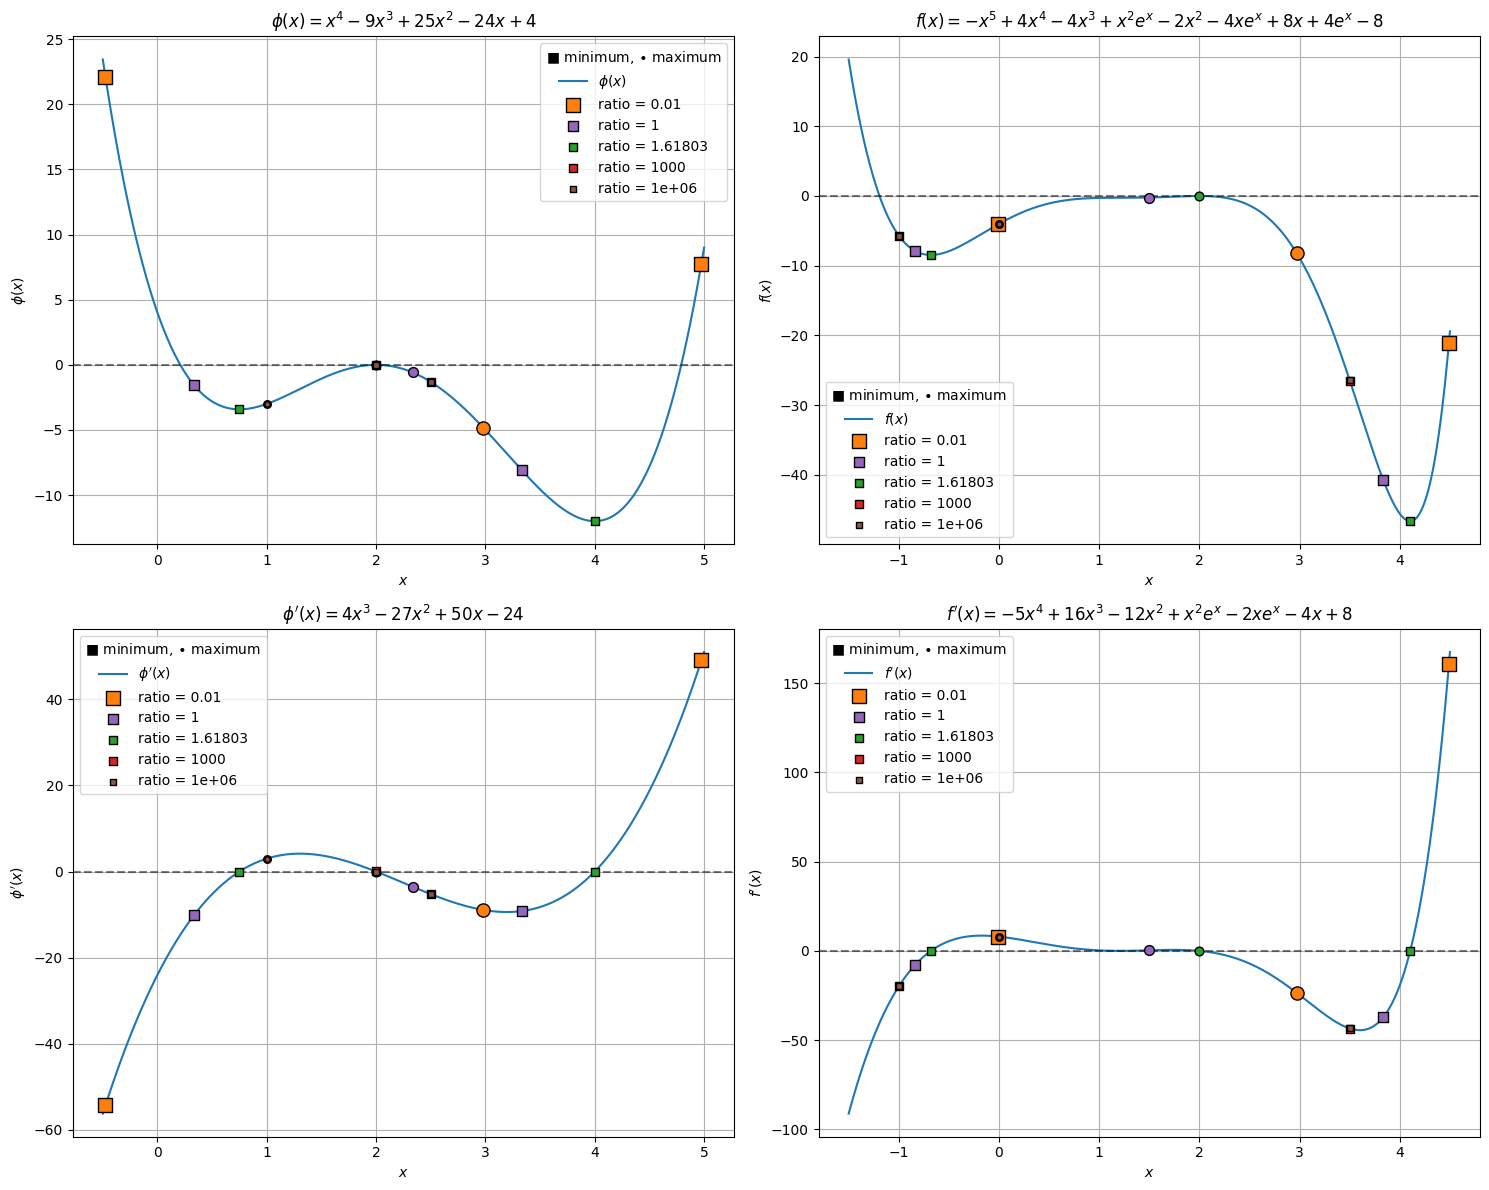

In [7]:
ratios = [1e-2, 1, golden_ratio, 1e3, 1e6]

x_1 = np.linspace(-0.5, 5, 5000)
y_1, y_1p = phi(x_1), phi_d(x_1)

x_2 = np.linspace(-1.5, 4.5, 1000)
y_2, y_2p = f(x_2), f_d(x_2)

fig, [[ax1, ax3], [ax2, ax4]] = plt.subplots(2, 2, figsize = (15, 12))

plot_config = [(ax1, x_1, y_1, r'$\phi(x)$', r'$\phi(x) = x^4 - 9x^3 + 25x^2 - 24x + 4$', r'$\phi(x)$'),
               (ax2, x_1, y_1p, r"$\phi'(x)$", r"$\phi'(x) = 4x^3 - 27x^2 + 50x - 24$", r"$\phi'(x)$"),
               (ax3, x_2, y_2, r'$f(x)$', r'$f(x) = -x^5 + 4x^4 - 4x^3 + x^2 e^x - 2x^2 - 4xe^x + 8x + 4e^x - 8$', r'$f(x)$'),
               (ax4, x_2, y_2p, r"$f'(x)$", r"$f'(x) = -5x^4 + 16x^3 - 12x^2 + x^2 e^x - 2xe^x - 4x + 8$", r"$f'(x)$")]

colors = ['tab:orange', 'tab:purple', 'tab:green', 'tab:red', 'tab:brown']
sizes = [90, 50, 40, 30, 15] # bigger markers are drawn first so overlapping points stay visible
functions = [phi, phi_d, f, f_d]

# plot the curves once
for ax, x, y, label, title, ylabel in plot_config:
    ax.plot(x, y, label=label)
    ax.axhline(y=0, c='black', ls='--', alpha=0.5)
    ax.set_title(title)
    ax.set_xlabel('$x$')
    ax.set_ylabel(ylabel)
    ax.grid(True)

# then add the extrema found by each ratio, one color per ratio
for new_ratio, color, size in zip(ratios, colors, sizes):
    phi_min1 = golden_search(func=phi, lower=-0.5, upper=2, varphi=new_ratio)
    phi_min2 = golden_search(func=phi, lower=2.5, upper=5, varphi=new_ratio)
    phi_min_r = np.array([phi_min1, phi_min2])

    f_min1 = golden_search(func=f, lower=-1, upper=0, varphi=new_ratio)
    f_min2 = golden_search(func=f, lower=3.5, upper=4.5, varphi=new_ratio)
    f_min_r = np.array([f_min1, f_min2])

    phi_max_r = np.array(golden_search(func=phi, lower=1, upper=3, minimum=False, varphi=new_ratio))
    f_max_r = np.array(golden_search(func=f, lower=0, upper=3, minimum=False, varphi=new_ratio))

    print(f"--- ratio = {new_ratio} ---")
    print(f"x-values of minimum of phi(x): {phi_min_r}\nx-values of minimum of f(x): {f_min_r}")
    print(f"x-values of maximum of phi(x): {phi_max_r}\nx-values of maximum of f(x): {f_max_r}")

    minimums = [phi_min_r, phi_min_r, f_min_r, f_min_r]
    maximums = [phi_max_r, phi_max_r, f_max_r, f_max_r]

    # color = ratio, marker shape = minimum (sq) or maximum (circ)
    for (ax, *_), mins, maxs, func in zip(plot_config, minimums, maximums, functions):
        ax.scatter(mins, func(mins), color=color, marker='s', s=size, edgecolors='black', zorder=3, label=f'ratio = {new_ratio:g}')
        ax.scatter(maxs, func(maxs), color=color, s=size, edgecolors='black', zorder=3)

for ax, *_ in plot_config:
    ax.legend(title=r'$\blacksquare$ minimum, $\bullet$ maximum')

plt.tight_layout()
plt.savefig("ratios.png", dpi=1000)
plt.show()

#### Problem 1 code summary

The extrema of each function were located using golden-section search, which starts from an initial bracketing interval and iteratively shrinks it by comparing the function at two interior points placed according to the golden ratio. To keep the code compact, the minimum and maximum searches were combined into a single function, with a keyword argument toggling between the two, and then extrema found were then plotted as markers on the graphs of the functions and their derivatives. Afterwards, the extrema was looped across a lists of ratios (including the golden ratio) to see what would happenn if we were to alter the value of the ratio.

---